# N-gram Language Models & Smoothing Comparison
### Introduction to Large Language Models — Assignment 4

This notebook reuses the **same corpus and train/dev/test splits** built in Assignment 3
(IndicCorp v2, one language, ~1,000,000 training sentences + 1000 dev + 1000 test, loaded from
`lab3_data/{LANGUAGE}_train_pool.parquet`, `_dev.parquet`, `_test.parquet`).

We build **unigram, bigram, trigram, and quadgram** models ($N=1,2,3,4$) under **5 smoothing
settings**, and compare their perplexities on dev and test.

**1. Unsmoothed (raw MLE):**
$$P(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n)}{C(w_1,\dots,w_{n-1})}$$

**2. Add-one (Laplace):**
$$P_{Laplace}(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n) + 1}{C(w_1,\dots,w_{n-1}) + V}$$

**3. Add-k** ($0 < k < 1$, we use $k=0.1$):
$$P_{AddK}(w_n \mid w_1,\dots,w_{n-1}) = \frac{C(w_1,\dots,w_n) + k}{C(w_1,\dots,w_{n-1}) + kV}$$

**4. Interpolated smoothing** — recursive linear (Jelinek-Mercer-style) interpolation with a
single interpolation constant $\lambda$ reused at every level. The assignment gives the base
case explicitly:
$$P_{smooth}(w_i) = \lambda P(w_i) + (1-\lambda)\frac{1}{V}$$
We extend this recursively for $n \ge 2$ (dropping the earliest context word at each
lower-order fallback, standard "shortened context" interpolation):
$$P_{smooth}^{(n)}(w_n \mid w_1,\dots,w_{n-1}) = \lambda\, P_{MLE}^{(n)}(w_n \mid w_1,\dots,w_{n-1}) + (1-\lambda)\, P_{smooth}^{(n-1)}(w_n \mid w_2,\dots,w_{n-1})$$

**5. Kneser-Ney (discount $d=0.75$)** — interpolated KN. At the model's own top order it
discounts raw counts and backs off; every lower order in the chain uses **continuation counts**
(how many *distinct* single-word contexts a sequence appears after) instead of raw counts, all
the way down to the base case:
$$P_{KN}(w_n \mid w_1,\dots,w_{n-1}) = \frac{\max(C(w_1,\dots,w_n) - d,\ 0)}{C(w_1,\dots,w_{n-1})} + \lambda(w_1,\dots,w_{n-1})\, P_{KN}(w_n \mid w_2,\dots,w_{n-1})$$
$$\lambda(w_1,\dots,w_{n-1}) = \frac{d \cdot N_{1+}(w_1,\dots,w_{n-1}, \bullet)}{C(w_1,\dots,w_{n-1})}, \qquad
P_{cont}(w) = \frac{N_{1+}(\bullet, w)}{N_{1+}(\bullet,\bullet)}$$
where $N_{1+}(w_1,\dots,w_{n-1},\bullet)$ is the number of distinct word types that follow the
context in training data, and the base case $P_{cont}(w)$ (used whenever we reach the unigram
level) is the fraction of distinct bigram types that end in $w$.

All five methods, all four orders (20 models total) are evaluated with the same corpus-level
perplexity: $PP = 2^{-\frac{1}{N}\sum \log_2 P(w_i \mid \text{context})}$ over every predicted
token in dev/test. **Unsmoothed higher-order models are expected to diverge to infinite
perplexity** the moment dev/test contains an n-gram never seen in training — this isn't a bug,
it's precisely the motivation for smoothing, and the comparison table makes it explicit.


## 0. Setup

In [1]:
%pip install -q pandas pyarrow numpy tqdm matplotlib


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import math
import pickle
from collections import Counter

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

LANGUAGE = "guj_Gujr"     # must match the LANGUAGE used in the Assignment 3 notebook
LAB3_DATA_DIR = "/Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-3/lab3_data"
ARTIFACTS_DIR = "lab4_artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

MAX_N = 4                 # quadgram is the highest order requested
MAX_TRAIN_SENTENCES = 1_000_000
UNK_MIN_COUNT = 2          # training words seen fewer than this many times become <unk>
ADD_K = 0.1                # 0 < k < 1, for Add-k smoothing
INTERP_LAMBDA = 0.4        # interpolation constant used at every level of interpolated smoothing
KN_DISCOUNT = 0.75

# QUICK_TEST shrinks the training set so the whole notebook can be sanity-checked in well under
# a minute before committing to the full 1,000,000-sentence run (which builds 4 orders of counts
# over a large corpus and is legitimately slow in pure Python).
QUICK_TEST = False
if QUICK_TEST:
    MAX_TRAIN_SENTENCES = 20_000

print(f"Language: {LANGUAGE}   QUICK_TEST={QUICK_TEST}   MAX_TRAIN_SENTENCES={MAX_TRAIN_SENTENCES:,}")


Language: guj_Gujr   QUICK_TEST=False   MAX_TRAIN_SENTENCES=1,000,000


## 1. Load the Assignment 3 corpus & splits

Reuses `lab3_data/{LANGUAGE}_train_pool.parquet`, `_dev.parquet`, `_test.parquet` exactly as
written by the Assignment 3 notebook (run that notebook first, through §3, if these aren't
present). Dev and test are already the length-stratified 1000-sentence sets from Assignment 3;
we just take the first `MAX_TRAIN_SENTENCES` training sentences from the shared training pool.


In [4]:
def _load(name):
    path = os.path.join(LAB3_DATA_DIR, f"{LANGUAGE}_{name}.parquet")
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Couldn't find {path}. Run the Assignment 3 notebook first (through \u00a73, "
            f"'Length-stratified train/dev/test split') so it writes "
            f"{LANGUAGE}_train_pool.parquet, {LANGUAGE}_dev.parquet, and {LANGUAGE}_test.parquet "
            f"into {LAB3_DATA_DIR}/."
        )
    return pd.read_parquet(path)

train_pool_df = _load("train_pool")
dev_df = _load("dev")
test_df = _load("test")

n_train = min(MAX_TRAIN_SENTENCES, len(train_pool_df))
if n_train < MAX_TRAIN_SENTENCES:
    print(f"WARNING: only {len(train_pool_df):,} training sentences available "
          f"(requested {MAX_TRAIN_SENTENCES:,}); using all of them.")

train_sentences_text = train_pool_df["text"].tolist()[:n_train]
dev_sentences_text = dev_df["text"].tolist()
test_sentences_text = test_df["text"].tolist()

print(f"train: {len(train_sentences_text):,}   dev: {len(dev_sentences_text)}   test: {len(test_sentences_text)}")


train: 1,000,000   dev: 1000   test: 1000


## 2. Tokenize & handle unknown words

Reuses the Unicode-aware word tokenizer from earlier assignments. Any training word seen fewer
than `UNK_MIN_COUNT` times is replaced with `<unk>` (and its count folded into `<unk>`'s count)
**before** any n-gram counting happens — this keeps the vocabulary finite and guarantees `<unk>`
itself has nonzero training counts, so smoothed models never choke on OOV words. Dev/test words
absent from the resulting vocabulary are mapped to `<unk>` the same way at evaluation time.


In [5]:
import regex

_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    return _WORD_RE.findall(sentence)

BOS, EOS, UNK = "<s>", "</s>", "<unk>"

train_tokenized_raw = [word_tokenize(s) for s in tqdm(train_sentences_text, desc="tokenizing train")]

word_freq = Counter()
for sent in train_tokenized_raw:
    word_freq.update(sent)

keep_vocab = {w for w, c in word_freq.items() if c >= UNK_MIN_COUNT}
print(f"raw unique words: {len(word_freq):,}   kept (count >= {UNK_MIN_COUNT}): {len(keep_vocab):,}")

def apply_unk(tokens, vocab):
    return [t if t in vocab else UNK for t in tokens]

train_tokenized = [apply_unk(sent, keep_vocab) for sent in train_tokenized_raw]
dev_tokenized = [apply_unk(word_tokenize(s), keep_vocab) for s in dev_sentences_text]
test_tokenized = [apply_unk(word_tokenize(s), keep_vocab) for s in test_sentences_text]

VOCAB = keep_vocab | {UNK, EOS}   # </s> must be predictable; <s> is context-only, excluded from V
V = len(VOCAB)
print(f"Vocabulary size V = {V:,} (includes <unk> and </s>; excludes <s>)")


tokenizing train: 100%|██████████| 1000000/1000000 [00:03<00:00, 279845.37it/s]


raw unique words: 516,809   kept (count >= 2): 225,682
Vocabulary size V = 225,684 (includes <unk> and </s>; excludes <s>)


## 3. N-gram counting (orders 1–4)

For order $n$, every sentence is padded with $n-1$ `<s>` tokens at the start and one `</s>` at
the end, then every contiguous window of length $n$ is an n-gram. We keep both the n-gram counts
and their $(n-1)$-length context counts (needed as the denominator for every smoothing method).


In [6]:
def pad_tokens(tokens, n):
    return [BOS] * (n - 1) + list(tokens) + [EOS]

def get_ngram_context_counts(tokenized_sentences, n):
    ngram_counts = Counter()
    context_counts = Counter()
    for tokens in tokenized_sentences:
        padded = pad_tokens(tokens, n)
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            ngram_counts[ngram] += 1
            context_counts[ngram[:-1]] += 1
    return ngram_counts, context_counts

COUNTS = {}   # n -> (ngram_counts, context_counts)
for n in range(1, MAX_N + 1):
    t0 = __import__("time").time()
    COUNTS[n] = get_ngram_context_counts(train_tokenized, n)
    ng, ctx = COUNTS[n]
    print(f"n={n}: {len(ng):,} distinct {n}-grams, {len(ctx):,} distinct contexts "
          f"({__import__('time').time() - t0:.1f}s)")


n=1: 225,684 distinct 1-grams, 1 distinct contexts (5.3s)
n=2: 4,954,846 distinct 2-grams, 225,684 distinct contexts (10.8s)
n=3: 9,984,173 distinct 3-grams, 4,922,710 distinct contexts (13.3s)
n=4: 12,189,324 distinct 4-grams, 9,743,471 distinct contexts (14.4s)


## 4. Smoothing methods (verified independently on a toy corpus before this notebook was written)

In [7]:
# ---------------- 1. Unsmoothed ----------------
def p_unsmoothed(ngram, n):
    ngram_counts, context_counts = COUNTS[n]
    context = ngram[:-1]
    c_ctx = context_counts.get(context, 0)
    if c_ctx == 0:
        return 0.0
    return ngram_counts.get(ngram, 0) / c_ctx


# ---------------- 2/3. Laplace / Add-k ----------------
def p_addk(ngram, n, k):
    ngram_counts, context_counts = COUNTS[n]
    context = ngram[:-1]
    c_ctx = context_counts.get(context, 0)
    c_ngram = ngram_counts.get(ngram, 0)
    return (c_ngram + k) / (c_ctx + k * V)

def p_laplace(ngram, n):
    return p_addk(ngram, n, 1.0)


# ---------------- 4. Interpolated (recursive linear interpolation) ----------------
def p_interp(ngram, n, lam=INTERP_LAMBDA):
    if n == 1:
        return lam * p_unsmoothed(ngram, 1) + (1 - lam) * (1.0 / V)
    higher = p_unsmoothed(ngram, n)
    lower = p_interp(ngram[1:], n - 1, lam)
    return lam * higher + (1 - lam) * lower


# ---------------- 5. Interpolated Kneser-Ney ----------------
def _build_kn_structures(global_max):
    raw_distinct_following = {}
    for n in range(1, global_max + 1):
        ngram_counts, _ = COUNTS[n]
        df = Counter()
        for ng in ngram_counts:
            df[ng[:-1]] += 1
        raw_distinct_following[n] = df

    cont_ngram_count, cont_context_total, cont_distinct_following = {}, {}, {}
    for n in range(1, global_max):
        ngram_counts_np1, _ = COUNTS[n + 1]
        cc = Counter()
        for ng in ngram_counts_np1:
            cc[ng[1:]] += 1
        cont_ngram_count[n] = cc

        ctx_total, df = Counter(), Counter()
        for ng, c in cc.items():
            ctx = ng[:-1]
            ctx_total[ctx] += c
            df[ctx] += 1
        cont_context_total[n] = ctx_total
        cont_distinct_following[n] = df

    return raw_distinct_following, cont_ngram_count, cont_context_total, cont_distinct_following

RAW_DF, CONT_NG, CONT_CTX_TOTAL, CONT_DF = _build_kn_structures(MAX_N)

def p_kn(ngram, n, top_n, d=KN_DISCOUNT):
    if n == 1:
        w = ngram[0]
        num = CONT_NG.get(1, Counter()).get((w,), 0)
        denom = CONT_CTX_TOTAL.get(1, Counter()).get((), 0)
        return num / denom if denom > 0 else 1.0 / V

    context = ngram[:-1]
    if n == top_n:
        ngram_counts, context_counts = COUNTS[n]
        c_ctx = context_counts.get(context, 0)
        if c_ctx == 0:
            return p_kn(ngram[1:], n - 1, top_n, d)
        c_ngram = ngram_counts.get(ngram, 0)
        n_types_following = RAW_DF[n].get(context, 0)
    else:
        c_ctx = CONT_CTX_TOTAL.get(n, Counter()).get(context, 0)
        if c_ctx == 0:
            return p_kn(ngram[1:], n - 1, top_n, d)
        c_ngram = CONT_NG.get(n, Counter()).get(ngram, 0)
        n_types_following = CONT_DF.get(n, Counter()).get(context, 0)

    discounted = max(c_ngram - d, 0) / c_ctx
    lam = (d * n_types_following) / c_ctx
    lower = p_kn(ngram[1:], n - 1, top_n, d)
    return discounted + lam * lower


SMOOTHING_METHODS = {
    "Unsmoothed":  lambda ngram, n: p_unsmoothed(ngram, n),
    "Laplace":     lambda ngram, n: p_laplace(ngram, n),
    f"Add-k(k={ADD_K})": lambda ngram, n: p_addk(ngram, n, ADD_K),
    f"Interpolated(\u03bb={INTERP_LAMBDA})": lambda ngram, n: p_interp(ngram, n),
    f"Kneser-Ney(d={KN_DISCOUNT})": lambda ngram, n: p_kn(ngram, n, n),
}
list(SMOOTHING_METHODS.keys())


['Unsmoothed',
 'Laplace',
 'Add-k(k=0.1)',
 'Interpolated(λ=0.4)',
 'Kneser-Ney(d=0.75)']

## 5. Perplexity

Corpus-level perplexity over every predicted token (i.e. every token except the leading `<s>`
padding) in a set of tokenized sentences:
$$PP = 2^{-\frac{1}{N}\sum_i \log_2 P(w_i \mid \text{context}_i)}$$
If any predicted token gets probability exactly 0 (only possible for the unsmoothed model, once
an unseen n-gram shows up), perplexity is `inf` by definition — we return `inf` directly rather
than crashing on `log(0)`.


In [8]:
def corpus_perplexity(tokenized_sentences, n, prob_fn):
    total_log_prob = 0.0
    total_tokens = 0
    for tokens in tokenized_sentences:
        padded = pad_tokens(tokens, n)
        for i in range(n - 1, len(padded)):
            ngram = tuple(padded[i - n + 1:i + 1])
            p = prob_fn(ngram, n)
            if p <= 0:
                return float("inf")
            total_log_prob += math.log2(p)
            total_tokens += 1
    return 2 ** (-total_log_prob / total_tokens)


## 6. Run all 20 models (4 orders × 5 smoothing methods) and compare perplexities

Each model is evaluated on both dev and test. This is the main experiment — expect the
`Unsmoothed` row to show `inf` for bigram and above (any dev/test bigram/trigram/quadgram
that never occurred in training makes the whole sentence's probability, and therefore the
corpus perplexity, zero/infinite) while every smoothed method stays finite.


In [9]:
results = []
for n in range(1, MAX_N + 1):
    for method_name, prob_fn in SMOOTHING_METHODS.items():
        t0 = __import__("time").time()
        dev_pp = corpus_perplexity(dev_tokenized, n, prob_fn)
        test_pp = corpus_perplexity(test_tokenized, n, prob_fn)
        dt = __import__("time").time() - t0
        results.append({"order": n, "method": method_name, "dev_perplexity": dev_pp,
                         "test_perplexity": test_pp, "eval_time_s": dt})
        print(f"n={n}  {method_name:22s}  dev_PP={dev_pp:>12.3f}  test_PP={test_pp:>12.3f}  ({dt:.1f}s)")

results_df = pd.DataFrame(results)
results_df


n=1  Unsmoothed              dev_PP=    3716.626  test_PP=    3850.024  (0.0s)
n=1  Laplace                 dev_PP=    3729.251  test_PP=    3858.420  (0.0s)
n=1  Add-k(k=0.1)            dev_PP=    3717.526  test_PP=    3850.417  (0.0s)
n=1  Interpolated(λ=0.4)     dev_PP=    6823.845  test_PP=    6946.656  (0.0s)
n=1  Kneser-Ney(d=0.75)      dev_PP=    5434.615  test_PP=    5533.704  (0.0s)
n=2  Unsmoothed              dev_PP=         inf  test_PP=         inf  (0.0s)
n=2  Laplace                 dev_PP=    9343.715  test_PP=    9898.033  (0.1s)
n=2  Add-k(k=0.1)            dev_PP=    3037.120  test_PP=    3250.449  (0.0s)
n=2  Interpolated(λ=0.4)     dev_PP=     923.145  test_PP=     948.481  (0.0s)
n=2  Kneser-Ney(d=0.75)      dev_PP=     592.874  test_PP=     617.679  (0.1s)
n=3  Unsmoothed              dev_PP=         inf  test_PP=         inf  (0.0s)
n=3  Laplace                 dev_PP=   61674.688  test_PP=   63272.294  (0.2s)
n=3  Add-k(k=0.1)            dev_PP=   30911.645  te

,order,method,dev_perplexity,test_perplexity,eval_time_s
0,1,Unsmoothed,3.716626e+03,3.850024e+03,0.028290
1,1,Laplace,3.729251e+03,3.858420e+03,0.011740
2,1,Add-k(k=0.1),3.717526e+03,3.850417e+03,0.010977
3,1,Interpolated(λ=0.4),6.823845e+03,6.946656e+03,0.010304
4,1,Kneser-Ney(d=0.75),5.434615e+03,5.533704e+03,0.027729
5,2,Unsmoothed,inf,inf,0.000247
6,2,Laplace,9.343715e+03,9.898033e+03,0.115394
7,2,Add-k(k=0.1),3.037120e+03,3.250449e+03,0.024180
8,2,Interpolated(λ=0.4),9.231448e+02,9.484809e+02,0.032671
9,2,Kneser-Ney(d=0.75),5.928737e+02,6.176789e+02,0.060171


In [10]:
pivot = results_df.pivot(index="method", columns="order", values="test_perplexity")
pivot = pivot.reindex(columns=[1, 2, 3, 4])
pivot.columns = [f"N={n}" for n in pivot.columns]
pivot


,N=1,N=2,N=3,N=4
method,,,,
Add-k(k=0.1),3850.416687,3250.448587,3.229474e+04,8.304709e+04
Interpolated(λ=0.4),6946.655686,948.480916,8.422170e+02,1.141229e+03
Kneser-Ney(d=0.75),5533.703761,617.678851,5.395339e+02,5.493842e+02
Laplace,3858.419777,9898.033475,6.327229e+04,1.151709e+05
Unsmoothed,3850.023546,inf,inf,inf


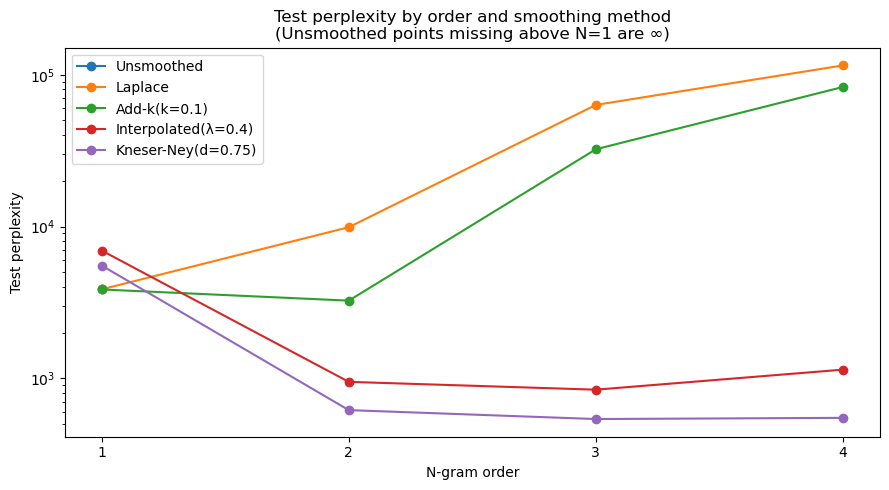

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for method_name in SMOOTHING_METHODS:
    sub = results_df[results_df["method"] == method_name].sort_values("order")
    finite = sub["test_perplexity"].replace([np.inf], np.nan)
    ax.plot(sub["order"], finite, marker="o", label=method_name)
ax.set_xlabel("N-gram order"); ax.set_ylabel("Test perplexity")
ax.set_yscale("log")
ax.set_xticks([1, 2, 3, 4])
ax.set_title("Test perplexity by order and smoothing method\n(Unsmoothed points missing above N=1 are \u221e)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Discussion helper — best method per order

In [12]:
finite_results = results_df.replace([np.inf], np.nan).dropna(subset=["test_perplexity"])
best_per_order = finite_results.loc[finite_results.groupby("order")["test_perplexity"].idxmin()]
best_per_order[["order", "method", "dev_perplexity", "test_perplexity"]]


,order,method,dev_perplexity,test_perplexity
0,1,Unsmoothed,3716.626092,3850.023546
9,2,Kneser-Ney(d=0.75),592.873669,617.678851
14,3,Kneser-Ney(d=0.75),514.133029,539.533851
19,4,Kneser-Ney(d=0.75),524.354887,549.384195


## 8. Save results

In [13]:
results_df.to_csv(os.path.join(ARTIFACTS_DIR, "ngram_smoothing_perplexity_comparison.csv"), index=False)

with open(os.path.join(ARTIFACTS_DIR, "ngram_counts.pkl"), "wb") as f:
    pickle.dump({"counts": {n: (dict(ng), dict(ctx)) for n, (ng, ctx) in COUNTS.items()},
                 "vocab": VOCAB, "V": V}, f)

print("Saved perplexity comparison table and raw n-gram counts to", ARTIFACTS_DIR)


Saved perplexity comparison table and raw n-gram counts to lab4_artifacts
